# DS2002 · Midterm Clinic Analysis and Charts

**Studio — 2026-10-28 · Fall 2026**  
**Class time:** 45 minutes

---

## Clinic — analysis and charts

Working session on your own project. The patterns below are the four analytical moves Questions 1 through 4 need; adapt each one to your cleaned data.

By the end of the hour you should have at least two charts you would be willing to put in the presentation on Monday.

In [1]:
import matplotlib.dates as mdates

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

DATA = '../data/'
NA = ['', 'NULL', 'N/A', 'NaN', 'nan']

decisions = []
def log(step, decision, rows):
    decisions.append({'step': step, 'decision': decision, 'rows_touched': int(rows)})


def clean_store_id(s):
    s = s.astype(str).str.strip().str.upper().str.replace('_', '-')
    return s.str.replace(r'^FL(\d{3})$', r'FL-\1', regex=True)

def parse_timestamps(s):
    formats = ['%Y-%m-%d %H:%M:%S', '%Y-%m-%dT%H:%M:%S', '%m/%d/%Y %H:%M', '%m-%d-%Y %H:%M:%S', '%d-%b-%Y %H:%M']
    out = pd.Series(pd.NaT, index=s.index, dtype='datetime64[ns]')
    for f in formats:
        out = out.combine_first(pd.to_datetime(s, format=f, errors='coerce'))
    return out

CATEGORY_MAP = {
    'emergency': 'Emergency', 'emergency supplies': 'Emergency',
    'grocery': 'Grocery', 'groceries': 'Grocery',
    'electronics': 'Electronics',
    'entertainment': 'Entertainment', 'games & entertainment': 'Entertainment',
    'household': 'Household', 'household essentials': 'Household',
    'baby': 'Baby', 'baby products': 'Baby',
    'breakfast': 'Breakfast', 'breakfast foods': 'Breakfast',
    'alcohol': 'Alcohol', 'alcoholic beverages': 'Alcohol',
    'snacks': 'Snacks',
    'health': 'Health', 'health & wellness': 'Health',
}

def clean_category(s):
    return s.str.strip().str.lower().map(CATEGORY_MAP)


def clean_transactions(raw):
    df = raw.copy()

    n = len(df)
    df = df.drop_duplicates()
    log('duplicates', 'dropped exact duplicate rows (same transaction_id and every other column)', n - len(df))
    assert df['transaction_id'].is_unique

    new = clean_store_id(df['store_id'])
    log('store_id', 'strip, uppercase, _ -> -, FL239 -> FL-239', (new != df['store_id']).sum())
    df['store_id'] = new

    price = df['unit_price'].astype(str).str.strip().str.lstrip('$')
    log('unit_price', 'removed $ and spaces, converted text to float', (price != df['unit_price']).sum())
    df['unit_price'] = pd.to_numeric(price, errors='raise')

    df['quantity'] = df['quantity'].astype(int)
    neg = df['quantity'] < 0
    log('quantity', 'dropped negative quantities (returns, not demand)', neg.sum())
    df = df[~neg]

    df['timestamp'] = parse_timestamps(df['timestamp'])
    missing = df['timestamp'].isna()
    log('timestamp', 'parsed 5 formats as local store time; dropped rows with no timestamp (blank/NULL/N/A/NaN)', missing.sum())
    df = df[~missing]

    cat = clean_category(df['category'])
    assert cat.notna().all()
    log('category', 'mapped 37 spellings onto 10 categories (names match the inventory db)', (cat != df['category']).sum())
    df['category'] = cat

    df['product_name'] = df['product_name'].str.strip()
    df['revenue'] = df['quantity'] * df['unit_price']
    return df.reset_index(drop=True)


def clean_stores(raw):
    df = raw.copy()
    df['store_id'] = clean_store_id(df['store_id'])
    n = len(df)
    df = df.drop_duplicates('store_id')
    log('stores', 'dropped duplicate store rows after fixing store_id (FL239, FL_287)', n - len(df))
    log('stores', 'state Florida / Fla. -> FL, stripped region', (df['state'] != 'FL').sum())
    df['state'] = 'FL'
    df['region'] = df['region'].str.strip()
    tlh = df['latitude'].isna()
    df.loc[df['store_id'] == 'FL-619', ['latitude', 'longitude']] = [30.4383, -84.2807]
    log('stores', 'filled missing lat/lon for FL-619 Tallahassee with city center coordinates', tlh.sum())
    df['tz'] = np.where(df['store_id'] == 'FL-710', 'America/Chicago', 'America/New_York')
    return df.reset_index(drop=True)


raw_tx = pd.read_csv(DATA + 'walmart_transactions.csv', dtype=str, keep_default_na=False)
raw_stores = pd.read_csv(DATA + 'store_locations.csv', na_values=NA)

tx = clean_transactions(raw_tx)
stores = clean_stores(raw_stores)

print('transactions:', len(raw_tx), '->', len(tx), f'({len(raw_tx) - len(tx)} removed)')
print('stores:', len(raw_stores), '->', len(stores))
print('store ids in tx:', tx['store_id'].nunique(), '| all join to store file:', tx['store_id'].isin(stores['store_id']).all())
print('date range:', tx['timestamp'].min(), 'to', tx['timestamp'].max())

import re

catalog = pd.read_csv(DATA + 'product_catalog.csv', na_values=NA)

PRODUCT_KEYWORDS = [
    ('pop-?tart', 'Pop-Tarts Strawberry'),
    ('water', 'Bottled Water 24-Pack'),
    ('batter', 'AA Batteries 4-Pack'),
    ('flashlight', 'LED Flashlight'),
    ('beer', 'Light Beer 24-Pack'),
    ('monopoly', 'Monopoly Board Game'),
    ('playing cards', 'Playing Cards'),
    ('roku|streaming', 'Roku Streaming Stick'),
    ('soup', 'Canned Soup'),
    ('bread', 'White Bread'),
    ('peanut', 'Peanut Butter'),
    ('candle', 'Emergency Candles'),
    ('first.aid', 'First Aid Kit'),
    ('charger', 'Portable Phone Charger'),
    ('chips', 'Chips Variety Pack'),
    ('paper towel', 'Paper Towels'),
    ('toilet', 'Toilet Paper 12-Roll'),
    ('diaper', 'Baby Diapers Size 3'),
    ('formula', 'Baby Formula'),
    ('tarp', 'Heavy Duty Tarp'),
]

def canonical_product(name):
    name = name.lower()
    hits = [p for kw, p in PRODUCT_KEYWORDS if re.search(kw, name)]
    assert len(hits) == 1, (name, hits)
    return hits[0]

def build_sku_map(catalog):
    m = catalog[['sku', 'product_name', 'category']].copy()
    m['product'] = m['product_name'].apply(canonical_product)
    m['category'] = clean_category(m['category'])
    return m

sku_map = build_sku_map(catalog)

print('categories per product:', sku_map.groupby('product')['category'].nunique().max())

before = tx['sku'].nunique()
tx['product'] = tx['sku'].map(sku_map.set_index('sku')['product'])
assert tx['product'].notna().all()

wrong_cat = (tx['category'] != tx['sku'].map(sku_map.set_index('sku')['category'])).sum()
log('sku', 'mapped 45 SKUs to 20 canonical products by keyword on the catalog name', len(tx))
print('transaction rows whose category disagrees with the catalog:', wrong_cat)

groups = sku_map.groupby('product')['sku'].apply(list)
print('distinct SKUs:', before, '-> canonical products:', tx['product'].nunique())
print('largest groups:', groups[groups.str.len() == groups.str.len().max()].to_dict())

LANDFALL = pd.Timestamp('2024-09-26')
BASE_START, BASE_END = '2024-09-01', '2024-09-14'
COLORS = ['#b4553f', '#4a5d7e', '#7f9c6c', '#d9a441', '#8c6bb1']

transactions: 25562 -> 24521 (1041 removed)
stores: 14 -> 12
store ids in tx: 12 | all join to store file: True
date range: 2024-09-01 06:01:15 to 2024-09-30 22:57:47
categories per product: 1
transaction rows whose category disagrees with the catalog: 0
distinct SKUs: 45 -> canonical products: 20
largest groups: {'Pop-Tarts Strawberry': ['PT-12', 'SKU#459812', 'POPTART-STRAW', 'PT_STRAWBERRY']}


### Pattern 1 — products moving together before landfall

One line per product, landfall marked. This is the Q1 chart, and it is the one that carries your presentation.

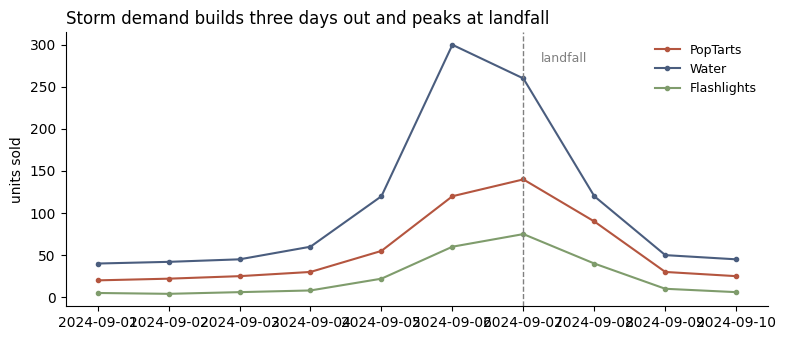

In [2]:
import pandas as pd, numpy as np, matplotlib.pyplot as plt

daily = pd.DataFrame({
    'date': pd.date_range('2024-09-01', periods=10),
    'PopTarts': [20, 22, 25, 30, 55, 120, 140, 90, 30, 25],
    'Water': [40, 42, 45, 60, 120, 300, 260, 120, 50, 45],
    'Flashlights': [5, 4, 6, 8, 22, 60, 75, 40, 10, 6],
}).set_index('date')
landfall = pd.Timestamp('2024-09-07')

fig, ax = plt.subplots(figsize=(8, 3.5))
for col, color in zip(daily.columns, ['#b4553f', '#4a5d7e', '#7f9c6c']):
    ax.plot(daily.index, daily[col], marker='o', ms=3, color=color, label=col)
ax.axvline(landfall, ls='--', color='gray', lw=1)
ax.annotate('landfall', xy=(landfall + pd.Timedelta(hours=6), 280),
            fontsize=9, color='gray')
ax.set_title('Storm demand builds three days out and peaks at landfall',
             loc='left', fontsize=12)
ax.set_ylabel('units sold')
ax.legend(frameon=False, fontsize=9)
for spine in ('top', 'right'):
    ax.spines[spine].set_visible(False)
plt.tight_layout()
plt.show()

**TODO:** rebuild that with your own cleaned categories and your own landfall date. Title it with what your data actually shows — if your surge peaks a day early, say that.

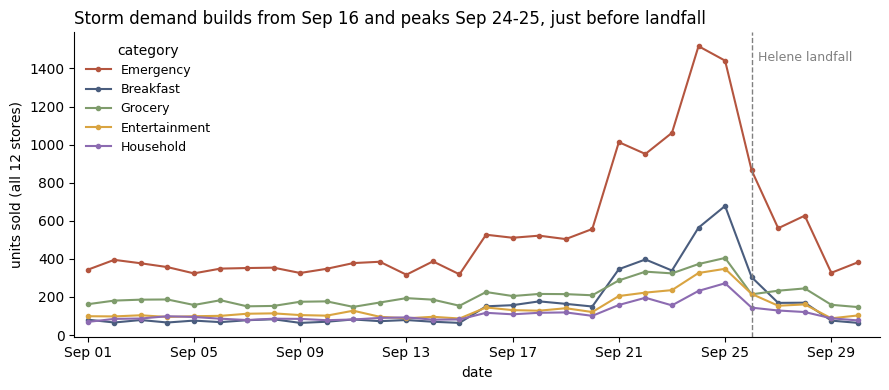

In [3]:
# TODO

tx['date'] = tx['timestamp'].dt.normalize()

cat_daily = tx.pivot_table(index='date', columns='category', values='quantity', aggfunc='sum').fillna(0)
top5 = cat_daily.loc['2024-09-16':'2024-09-26'].sum().nlargest(5).index

fig, ax = plt.subplots(figsize=(9, 4))
for col, color in zip(top5, COLORS):
    ax.plot(cat_daily.index, cat_daily[col], marker='o', ms=3, color=color, label=col)
ax.axvline(LANDFALL, ls='--', color='gray', lw=1)
ax.annotate('Helene landfall', xy=(LANDFALL + pd.Timedelta(hours=6), cat_daily[top5].max().max() * 0.95),
            fontsize=9, color='gray')
ax.set_title('Storm demand builds from Sep 16 and peaks Sep 24-25, just before landfall',
             loc='left', fontsize=12)
ax.set_xlabel('date')
ax.set_ylabel('units sold (all 12 stores)')
ax.xaxis.set_major_locator(mdates.DayLocator(bymonthday=range(1, 31, 4)))
ax.xaxis.set_major_formatter(mdates.DateFormatter('%b %d'))
ax.set_xlim(pd.Timestamp('2024-08-31 12:00'), pd.Timestamp('2024-09-30 20:00'))
ax.legend(frameon=False, fontsize=9, title='category')
for spine in ('top', 'right'):
    ax.spines[spine].set_visible(False)
plt.tight_layout()
plt.show()

### Pattern 2 — indexing to baseline so different products are comparable

Water outsells flashlights ten to one, so on a raw chart the flashlight surge is invisible. Divide each series by its own pre-storm average and every product starts at 1.0 — now you are comparing *how much each one moved*, which is the actual question.

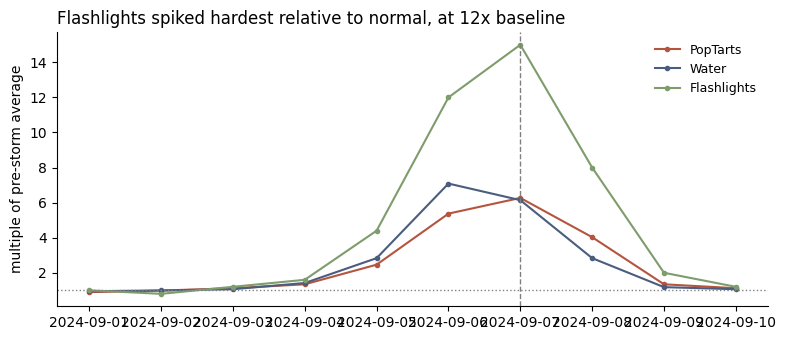

Flashlights    15.0
Water           7.1
PopTarts        6.3
dtype: float64


In [4]:
baseline = daily[daily.index < landfall - pd.Timedelta(days=3)].mean()
indexed = daily / baseline

fig, ax = plt.subplots(figsize=(8, 3.5))
for col, color in zip(indexed.columns, ['#b4553f', '#4a5d7e', '#7f9c6c']):
    ax.plot(indexed.index, indexed[col], marker='o', ms=3, color=color, label=col)
ax.axhline(1.0, ls=':', color='gray', lw=1)
ax.axvline(landfall, ls='--', color='gray', lw=1)
ax.set_title('Flashlights spiked hardest relative to normal, at 12x baseline',
             loc='left', fontsize=12)
ax.set_ylabel('multiple of pre-storm average')
ax.legend(frameon=False, fontsize=9)
for spine in ('top', 'right'):
    ax.spines[spine].set_visible(False)
plt.tight_layout()
plt.show()

print(indexed.max().round(1).sort_values(ascending=False))

Two charts, same data, different findings. The raw chart says water is the story; the indexed chart says flashlights are. Both belong in the presentation, in that order.

**TODO:** index your own products to their baseline and see whether your ranking changes.

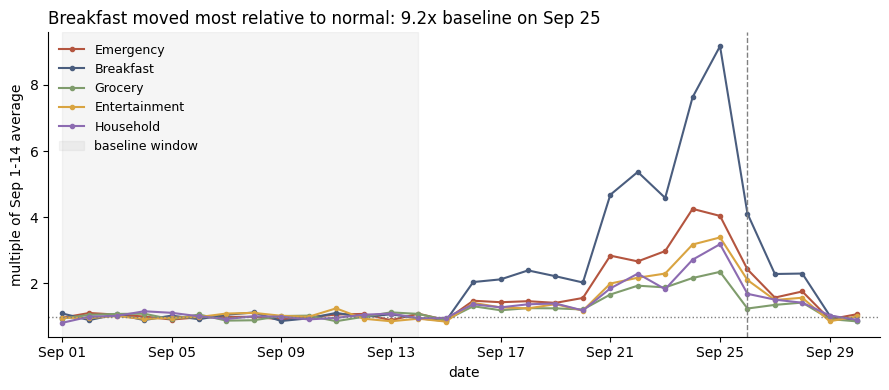

peak multiple by category (baseline Sep 1-14):
category
Breakfast        9.2
Emergency        4.3
Electronics      4.0
Health           3.5
Entertainment    3.4
Household        3.2
Alcohol          3.1
Grocery          2.4
Baby             2.0
Snacks           1.6
dtype: float64



top 5 products by peak multiple:
product
Pop-Tarts Strawberry     9.2
LED Flashlight           5.0
Bottled Water 24-Pack    4.6
Heavy Duty Tarp          4.5
Emergency Candles        4.4
dtype: float64


In [5]:
# TODO

cat_base = cat_daily.loc[BASE_START:BASE_END].mean()
cat_indexed = cat_daily / cat_base
leader = cat_indexed.max().idxmax()

fig, ax = plt.subplots(figsize=(9, 4))
for col, color in zip(top5, COLORS):
    ax.plot(cat_indexed.index, cat_indexed[col], marker='o', ms=3, color=color, label=col)
ax.axhline(1.0, ls=':', color='gray', lw=1)
ax.axvline(LANDFALL, ls='--', color='gray', lw=1)
ax.axvspan(pd.Timestamp(BASE_START), pd.Timestamp(BASE_END), color='gray', alpha=0.08, label='baseline window')
ax.set_title(f'{leader} moved most relative to normal: {cat_indexed[leader].max():.1f}x baseline on {cat_indexed[leader].idxmax():%b %d}',
             loc='left', fontsize=12)
ax.set_xlabel('date')
ax.set_ylabel('multiple of Sep 1-14 average')
ax.xaxis.set_major_locator(mdates.DayLocator(bymonthday=range(1, 31, 4)))
ax.xaxis.set_major_formatter(mdates.DateFormatter('%b %d'))
ax.set_xlim(pd.Timestamp('2024-08-31 12:00'), pd.Timestamp('2024-09-30 20:00'))
ax.legend(frameon=False, fontsize=9)
for spine in ('top', 'right'):
    ax.spines[spine].set_visible(False)
plt.tight_layout()
plt.show()

print('peak multiple by category (baseline Sep 1-14):')
print(cat_indexed.max().round(1).sort_values(ascending=False))

prod_daily = tx.pivot_table(index='date', columns='product', values='quantity', aggfunc='sum').fillna(0)
prod_indexed = prod_daily / prod_daily.loc[BASE_START:BASE_END].mean()
print()
print('top 5 products by peak multiple:')
print(prod_indexed.max().round(1).nlargest(5))

### Pattern 3 — before-and-after for Q2

The SKU consolidation question needs a comparison, not a description. Show the number somebody would have reported without your work next to the number with it.

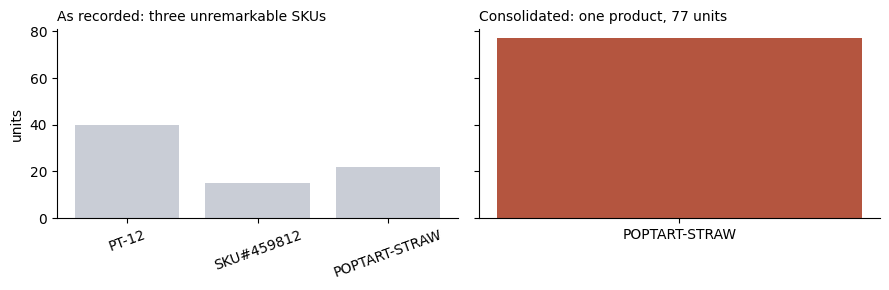

In [6]:
fragmented = pd.Series({'PT-12': 40, 'SKU#459812': 15, 'POPTART-STRAW': 22})
consolidated = pd.Series({'POPTART-STRAW': 77})

fig, axes = plt.subplots(1, 2, figsize=(9, 3), sharey=True)
axes[0].bar(fragmented.index, fragmented.values, color='#c9cdd6')
axes[0].set_title('As recorded: three unremarkable SKUs', fontsize=10, loc='left')
axes[0].tick_params(axis='x', labelrotation=20)
axes[1].bar(consolidated.index, consolidated.values, color='#b4553f')
axes[1].set_title('Consolidated: one product, 77 units', fontsize=10, loc='left')
axes[0].set_ylabel('units')
for ax in axes:
    for spine in ('top', 'right'):
        ax.spines[spine].set_visible(False)
plt.tight_layout()
plt.show()

**TODO:** build this for your largest consolidated product family. State the multiple.

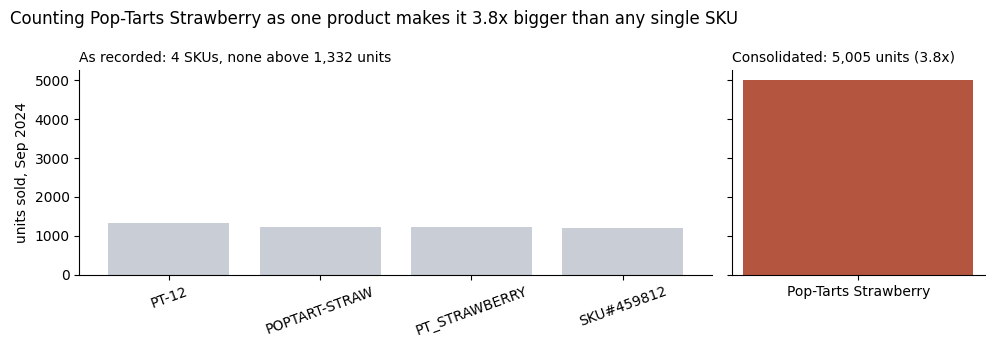

largest Pop-Tarts Strawberry SKU ranks #8 of 45 SKUs
Pop-Tarts Strawberry as one product ranks #2 of 20 products


In [7]:
# TODO

family = sku_map.groupby('product')['sku'].size().idxmax()
fam = tx[tx['product'] == family]
fragmented = fam.groupby('sku')['quantity'].sum().sort_values(ascending=False)
combined = fragmented.sum()
multiple = combined / fragmented.max()

sku_rank = tx.groupby('sku')['quantity'].sum().rank(ascending=False)[fragmented.index[0]]
prod_rank = tx.groupby('product')['quantity'].sum().rank(ascending=False)[family]

fig, axes = plt.subplots(1, 2, figsize=(10, 3.5), sharey=True, gridspec_kw={'width_ratios': [len(fragmented), 1.6]})
axes[0].bar(fragmented.index, fragmented.values, color='#c9cdd6')
axes[0].set_title(f'As recorded: {len(fragmented)} SKUs, none above {fragmented.max():,} units', fontsize=10, loc='left')
axes[0].tick_params(axis='x', labelrotation=20)
axes[1].bar([family], [combined], color='#b4553f')
axes[1].set_title(f'Consolidated: {combined:,} units ({multiple:.1f}x)', fontsize=10, loc='left')
axes[0].set_ylabel('units sold, Sep 2024')
for ax in axes:
    for spine in ('top', 'right'):
        ax.spines[spine].set_visible(False)
fig.suptitle(f'Counting {family} as one product makes it {multiple:.1f}x bigger than any single SKU', x=0.01, ha='left', fontsize=12)
plt.tight_layout()
plt.show()

print(f'largest {family} SKU ranks #{sku_rank:.0f} of {tx["sku"].nunique()} SKUs')
print(f'{family} as one product ranks #{prod_rank:.0f} of {tx["product"].nunique()} products')

### Pattern 4 — Q4, stores by distance

Aggregate by store, join whatever geography you have, and look for the gradient. Watch the group sizes — a store with four transactions will produce a wild average.

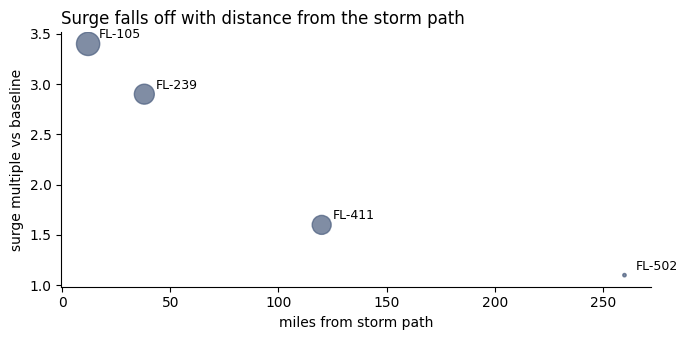

note the smallest bubble: FL-502 has only 90 transactions,
so its 1.1x is barely distinguishable from noise.


In [8]:
by_store = pd.DataFrame({
    'store_id': ['FL-105', 'FL-239', 'FL-411', 'FL-502'],
    'surge_multiple': [3.4, 2.9, 1.6, 1.1],
    'miles_from_path': [12, 38, 120, 260],
    'transactions': [4200, 3100, 2800, 90],
})

fig, ax = plt.subplots(figsize=(7, 3.5))
sizes = by_store['transactions'] / 15
ax.scatter(by_store['miles_from_path'], by_store['surge_multiple'],
           s=sizes, alpha=0.7, color='#4a5d7e')
for row in by_store.itertuples():
    ax.annotate(row.store_id, (row.miles_from_path, row.surge_multiple),
                textcoords='offset points', xytext=(8, 4), fontsize=9)
ax.set_title('Surge falls off with distance from the storm path',
             loc='left', fontsize=12)
ax.set_xlabel('miles from storm path')
ax.set_ylabel('surge multiple vs baseline')
for spine in ('top', 'right'):
    ax.spines[spine].set_visible(False)
plt.tight_layout()
plt.show()

print('note the smallest bubble: FL-502 has only 90 transactions,')
print('so its 1.1x is barely distinguishable from noise.')

Sizing the points by transaction count is doing real work here — it tells the reader which points to trust. A four-point scatter is not a trend line, and you should say so out loud rather than fitting one.

**TODO:** build your version. If you only have a handful of stores, present it as a table with a comment instead of a scatter — a chart with five points and a regression line will get asked about.

In [9]:
# TODO

LANDFALL_LAT, LANDFALL_LON = 30.0, -83.8

def miles_between(lat1, lon1, lat2, lon2):
    lat1, lon1, lat2, lon2 = map(np.radians, [lat1, lon1, lat2, lon2])
    a = np.sin((lat2 - lat1) / 2) ** 2 + np.cos(lat1) * np.cos(lat2) * np.sin((lon2 - lon1) / 2) ** 2
    return 3958.8 * 2 * np.arcsin(np.sqrt(a))

store_daily = tx.groupby(['store_id', 'date'])['quantity'].sum().unstack(0)
by_store = stores.set_index('store_id')[['city', 'region', 'latitude', 'longitude']].copy()
by_store['miles_to_landfall'] = miles_between(by_store['latitude'], by_store['longitude'], LANDFALL_LAT, LANDFALL_LON).round(0)
by_store['baseline_units_per_day'] = store_daily.loc[BASE_START:BASE_END].mean().round(1)
by_store['surge_units_per_day'] = store_daily.loc['2024-09-21':'2024-09-25'].mean().round(1)
by_store['surge_multiple'] = (by_store['surge_units_per_day'] / by_store['baseline_units_per_day']).round(2)
by_store['transactions'] = tx['store_id'].value_counts()
by_store = by_store.drop(columns=['latitude', 'longitude']).sort_values('miles_to_landfall')

rho = by_store['miles_to_landfall'].corr(by_store['surge_multiple'], method='spearman')
print(f"surge multiple range: {by_store['surge_multiple'].min()}x to {by_store['surge_multiple'].max()}x across {len(by_store)} stores")
print(f'spearman rank correlation, distance vs surge: {rho:.2f}')
by_store

surge multiple range: 2.6x to 3.2x across 12 stores
spearman rank correlation, distance vs surge: -0.08


,city,region,miles_to_landfall,baseline_units_per_day,surge_units_per_day,surge_multiple,transactions
store_id,,,,,,,
FL-619,Tallahassee,Panhandle,42.0,86.4,257.4,2.98,1981
FL-078,Gainesville,North,92.0,92.1,256.2,2.78,2001
FL-412,Jacksonville,North,130.0,91.1,262.8,2.88,2028
FL-105,Tampa,West,163.0,91.8,278.6,3.03,2043
FL-445,St. Petersburg,West,169.0,95.9,272.8,2.84,2074
FL-156,Daytona Beach,East,176.0,95.2,268.8,2.82,2074
FL-302,Lakeland,Central,176.0,98.0,286.0,2.92,2123
FL-239,Orlando,Central,177.0,94.4,245.2,2.60,2010
FL-287,Kissimmee,Central,186.0,91.0,256.2,2.82,2053


### Before you leave

- At least two presentation-ready charts, each with a message title
- Q1 has a stated baseline window and a multiple
- Q2 has a before-and-after comparison
- Everything pushed

Monday is presentations. The timing breakdown and the self-check are in Monday's notebook — read it tonight, not Monday morning.

---

## Checkpoint (participation)

Report the surge multiple you found for your top product and the baseline window you used to get it.

Work in groups if you wish, then fill in the cell below **yourself**. Paste the printed output (or a screenshot of it) into this week's **Studio Checkpoint** in Canvas by **Thursday 11:59pm ET**. One submission per person, not per group.

In [10]:
# Checkpoint
top_product = 'Pop-Tarts Strawberry'         # TODO: your biggest mover
surge_multiple = 9.2        # TODO: how many times baseline
baseline_window = 'Sep 1-14 (14 days before the first step-up on Sep 16, landfall Sep 26)'     # TODO: e.g. '14 days before Sept 4'
charts_ready = 3          # TODO: how many presentation-ready charts you have

print('top product:', top_product)
print('surge multiple:', surge_multiple)
print('baseline window:', baseline_window)
print('charts ready:', charts_ready)

top product: Pop-Tarts Strawberry
surge multiple: 9.2
baseline window: Sep 1-14 (14 days before the first step-up on Sep 16, landfall Sep 26)
charts ready: 3
